In [1]:
import os
import tensorflow as tf
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import json

from tensorflow.keras import layers, models
from keras.models import Sequential, Model
from keras.losses import MeanSquaredError
from keras.layers import *
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

import DAE_DataGenerator
import importlib
importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_DG
from OptimizedDataGenerator_v2 import OptimizedDataGenerator as NewDG
from OptimizedDataGenerator_v2p5 import OptimizedDataGenerator as JennetDG

from loss import *
import models
importlib.reload(models)
from models import *
from dataset_utils import *
import plotting
importlib.reload(plotting)
from plotting import *

import training_metadata
importlib.reload(training_metadata)
from training_metadata import *


pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-07-07 14:46:13.475649: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
'''Load data for regression training'''
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")
tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'3sr_16x16_80eN_raw_slim')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3sr_16x16_80eN_raw_slim')


validation_generator = NewDG(
    load_from_tfrecords_dir = tfrecords_dir_val,
)
training_generator = NewDG(
    load_from_tfrecords_dir = tfrecords_dir_train,
)

print(validation_generator.labels_scale)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3sr_16x16_80eN_raw_slim/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3sr_16x16_80eN_raw_slim/metadata.json


[99.17029747 24.79370923  1.89031215]


In [2]:
with open('training_dict_new.json', 'r') as file:
    train_dict = json.load(file)
for k, n in train_dict.items():
    print(k)
    # print(n)

SQDAE_MaxConv2D_T240e_2x2bitEncoder
SQDAE_MaxConv2D_T80e_2x2bitEncoder
SQDAE_MaxConv2D_T0e_2x2bitEncoder
MC2D_T240e_2bit
SQDAE_T240e_2x2bitEncoder
MC2D_T80e_2bit
SQDAE_T80e_2x2bitEncoder
SQDAE_T0e_2x2bitEncoder
SQDAE_T80e_2x3bitEncoder
MC2D_T0e_2bit


In [4]:
'''Generate residuals'''
with open('training_dict_new.json', 'r') as file:
    train_dict = json.load(file)
# for k, n in train_dict.items():
#     print(k)
    # print(n)
# BEGIN LOOP ---------------------------------------------------------------------
for key, meta in train_dict.items():
    print(key)
    # print(i, path)
    NOISE_SIGMA = meta['noise']
    path = meta["weights"]
    tfrecords_dir_val = meta['tfr']
    
    if 'jennet' in path:
        #Get best checkpoint:
        checkpoint_dir = path
        checkpoint_files = [os.path.join(checkpoint_dir, f) for f in os.listdir(checkpoint_dir) if f.endswith('.hdf5')]
        # latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
        checkpoint_val_loss = [float(f.split('-v')[1].split('.hdf5')[0]) for f in checkpoint_files]                      
        best_checkpoint = checkpoint_files[np.argmin(checkpoint_val_loss)]
        #Construct model
        model=CreateSQMaxconv2DModel((16,16,2),n_filters=5,pool_size=3,conv_kernel_size=3,
                          # mean_filter=mean_filter[i], thresh = thresh[i]
                         )
        #Get dataset
        # jennet_tfrecords = "/uscms/home/jennetd/nobackup/smart-pixels/tfrecords"
        # tfrecords_dir_val   = os.path.join(jennet_tfrecords, "TFR_val",'3sr_16x16_'+str(int(NOISE_SIGMA))+'eNoise_test')
        test_generator = JennetDG(
            load_from_tfrecords_dir= tfrecords_dir_val,
            shuffle=True,
            quantize=False,
        )
    else: #Ben's network
        #Get Best checkpoint
        checkpoint_files = [os.path.join(path, f) for f in os.listdir(path) if f.endswith('.hdf5')]
        best_checkpoint = max(checkpoint_files, key=os.path.getmtime)
        
        #Construct model
        if meta["model_type"] == 'SQDAE_Conv2D':
            print(key, "is a SQDAE_MaxConv2Dregression model")
            model = CreateSQMaxconv2DModel(shape = (16,16,2), n_filters=5, pool_size=3, conv_kernel_size = 3)

        elif meta["model_type"] == 'SQDAE':
            print(key, "is a SQDAE model")
            DAE=CreateSQAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                            decoder_filters = 128, 
                            xrange = None
                           )
            layer_name = DAE.layers[9].name
            print(layer_name)
            encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
            encoder.trainable = False
            x_in = encoder.input
            lat_shape = encoder.output.shape
            dense_net = var_network(encoder.output, hidden=16, output=14)
            model = Model(inputs=x_in, outputs=dense_net)
        elif meta["model_type"] == 'Conv2D':
            print(key, "is a MaxConv2D model")
            model = CreateSQMaxconv2DModel(shape = (16,16,2), n_filters=5, pool_size=3, conv_kernel_size = 3)
         #Get dataset
        test_generator = NewDG(
            load_from_tfrecords_dir= tfrecords_dir_val,
            shuffle=True,
            quantize=False,
        )

    

    print(f"Loading model from {best_checkpoint}")
    model.load_weights(best_checkpoint)

    sf = test_generator.labels_scale

    scale_factor = {}
    scale_factor['x'] = sf[0]
    scale_factor['y'] = sf[1]
    scale_factor['cotA'] = sf[2]
    scale_factor['cotB'] = sf[3]

    df = construct_df(model, test_generator, scale_factor)
    df.to_parquet('./SQ_DAE_regression/residuals/'+f"{key}_residuals.parquet")
    # residuals[i] = df

SQDAE_MaxConv2D_T240e_2x2bitEncoder
SQDAE_MaxConv2D_T240e_2x2bitEncoder is a SQDAE_MaxConv2Dregression model
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_240eN_raw/metadata.json


Loading model from ./SQ_DAE_regression/model-ac3e95e5-SQDAE_MaxConv2Dregression_Categorical2bit_240eN_Target_0_30_856-checkpoints/weights.1933-t-20709.18-v-22604.45.hdf5
21/21 [==============================] - 3s 142ms/step


100%|██████████| 21/21 [00:01<00:00, 15.43it/s]


0.20169258 -0.60974187 1.0162302
SQDAE_MaxConv2D_T80e_2x2bitEncoder
SQDAE_MaxConv2D_T80e_2x2bitEncoder is a SQDAE_MaxConv2Dregression model
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_80eN_raw/metadata.json


Loading model from ./SQ_DAE_regression/model-1e63a561-SQDAE_MaxConv2Dregression_Categorical2bit_80eN_Target_0_30_856_V2-checkpoints/weights.1540-t-25988.65-v-27476.31.hdf5
21/21 [==============================] - 2s 83ms/step


...

100%|██████████| 21/21 [00:01<00:00, 18.76it/s]


0.041604407 -1.0083591 1.0082703
MC2D_T0e_2bit
Loading metadata from /uscms/home/jennetd/nobackup/smart-pixels/tfrecords/TFR_val/3sr_16x16_0eNoise_test/metadata.json


Loading model from /uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models//model-60350e7e-MaxConv2D_SQ_0e_2bit-checkpoints/weights.1980-t-24837.41-v-27445.59.hdf5
21/21 [==============================] - 4s 181ms/step


100%|██████████| 21/21 [00:01<00:00, 14.84it/s]


0.20174779 -0.60974187 1.0162302


In [13]:
def format_plot(ax, n_models, slim=False):
    ax[1][0].plot([0,0],[-1-n_models,1],color='gray', zorder=0)
    ax[1][1].plot([0,0],[-1-n_models,1],color='gray', zorder=0)
    ax[1][2].plot([0,0],[-1-n_models,1],color='gray', zorder=0)
    ax[1][3].plot([0,0],[-1-n_models,1],color='gray', zorder=0)
    
    ax[1][0].set_ylim(0.5-n_models,0.5)
    ax[1][1].set_ylim(0.5-n_models,0.5)
    ax[1][2].set_ylim(0.5-n_models,0.5)
    ax[1][3].set_ylim(0.5-n_models,0.5)
    
vbl_names = {'x':r'$R_x$ [um]', 'y':r'$R_y$ [um]', 'A':r'$R_\alpha$ [deg]', 'B':r'$R_\beta$ [deg]'}

{'MC2D_T240e_2bit': 'MaxConv2D T240e 2bit FE', 'SQDAE_T240e_2x2bitEncoder': 'SQAutoEncoder T240e 2bitFE 2bitEncoder', 'MC2D_T80e_2bit': 'MaxConv2D T80e 2bit FE', 'SQDAE_T80e_2x3bitEncoder': 'SQAutoEncoder T80e 2bitFE 3bitEncoder', 'SQDAE_T80e_2x2bitEncoder': 'SQAutoEncoder T80e 2bitFE 2bitEncoder', 'MC2D_T0e_2bit': 'MaxConv2D T0e 2bit FE'}
Model = MC2D_T240e_2bit --------------
Model = SQDAE_T240e_2x2bitEncoder --------------
Model = MC2D_T80e_2bit --------------
Model = SQDAE_T80e_2x3bitEncoder --------------
Model = SQDAE_T80e_2x2bitEncoder --------------
Model = MC2D_T0e_2bit --------------


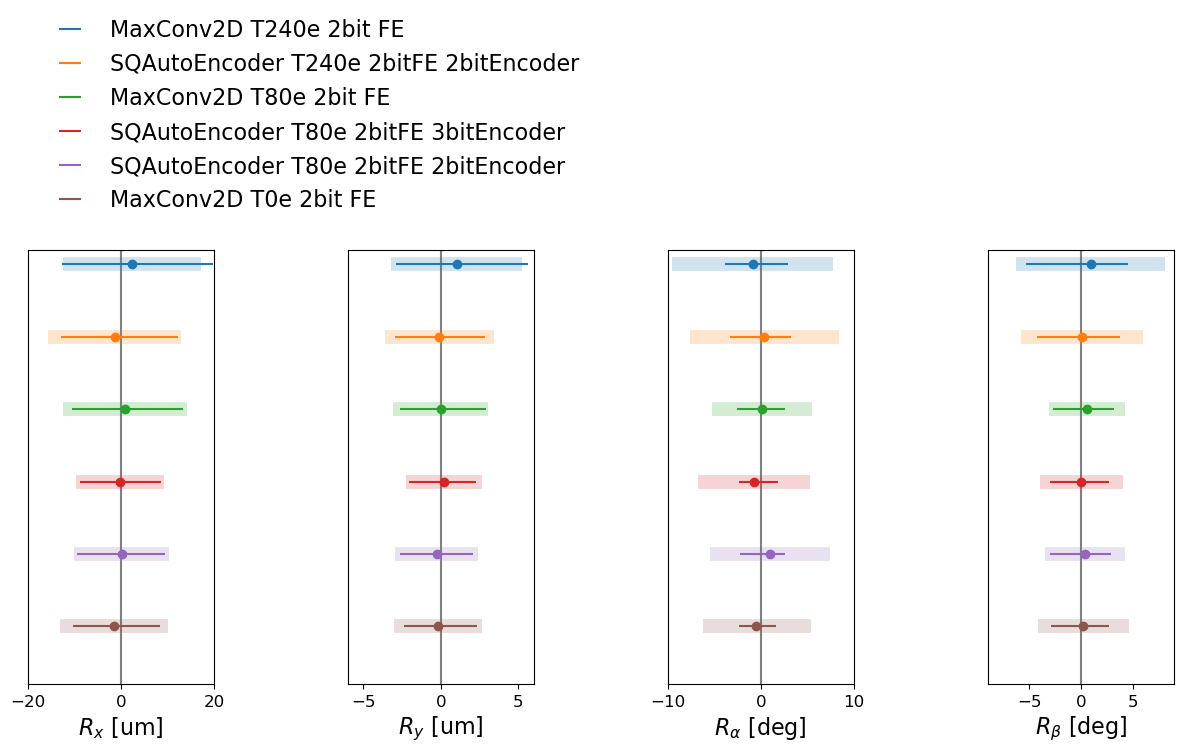

In [14]:
import plotting 
plt.rcParams['legend.markerscale'] = 1.0

fig, ax = plt.subplots(2,4,figsize=(12,8),sharey=True, constrained_layout=True, gridspec_kw={'height_ratios': [1, 2]})

ax[0,0].axis('off')
ax[0,1].axis('off')
ax[0,2].axis('off')
ax[0,3].axis('off')
# ax[0,4].axis('off')


if names is not None:
    names = {}
    names['MC2D_T240e_2bit'] = 'MaxConv2D T240e 2bit FE'
    names['SQDAE_T240e_2x2bitEncoder'] = 'SQAutoEncoder T240e 2bitFE 2bitEncoder'
    names['MC2D_T80e_2bit'] = 'MaxConv2D T80e 2bit FE'
    names['SQDAE_T80e_2x3bitEncoder'] = 'SQAutoEncoder T80e 2bitFE 3bitEncoder'
    names['SQDAE_T80e_2x2bitEncoder'] = 'SQAutoEncoder T80e 2bitFE 2bitEncoder'
    names['MC2D_T0e_2bit'] = 'MaxConv2D T0e 2bit FE'

    print(names)
else:
    names = {}
    # names['Transformer0e_2bit'] = 'transformer 0e, 2 bits'
    # names['Transformer0e_3bit'] = 'transformer 0e, 3 bits'
    # names['Transformer0e_full'] = 'transformer 0e, full precision'

labels = list(names.keys())

format_plot(ax, len(labels))

lines = []

for i,k1 in enumerate(labels):
    
        
    print("Model = " + k1 + " --------------")
    
    line, dots = draw_one_model(i, residuals[k1], labels, ax, vbl_names)
    lines += [line[0]]
    
gs = ax[0, 2].get_gridspec()
ax[0,0].remove()
ax[0,1].remove()
# ax[1,0].remove()
# print([n for k, n in names.items()])
# fig.legend(labels, fontsize = fontsize, x=0, y=0.9)

axbig = fig.add_subplot(gs[0, 0:2])
axbig.axis('off')
axbig.legend(lines, [n for k, n in names.items()], frameon=False, loc='lower left', fontsize=fontsize)

# axbig.legend(lines,[names[l] for l in labels],frameon=False,loc='lower left',fontsize=fontsize)
# axbig.legend(dots,[n for k, n in names.items()],fontsize=fontsize,frameon=False,loc='lower left')

# x limits
ax[1][0].set_xlim(-20,20) # x
ax[1][1].set_xlim(-6,6) # y
ax[1][2].set_xlim(-10,10) # alpha
ax[1][3].set_xlim(-9,9) # reset beta

plt.tight_layout()

#plt.savefig("dataset3sr/plots/res-max-full.pdf")
#plt.savefig("dataset3sr/plots/res-max-full.png")

plt.show()

SQDAE_T0e_2x2bitEncoder
SQDAE_T80e_2x2bitEncoder
MC2D_T0e_2bit
MC2D_T80e_2bit
MC2D_T240e_2bit
SQDAE_MaxConv2D_T0e_2x2bitEncoder
SQDAE_MaxConv2D_T80e_2x2bitEncoder
SQDAE_MaxConv2D_T240e_2x2bitEncoder
   noise    x_width   y_width   A_width   B_width
0      0  19.548223  5.047854  4.720726  6.077354
0     80  20.689560  4.999839  4.435846  5.732620
0    240  24.531307  6.000450  6.029221  9.988777


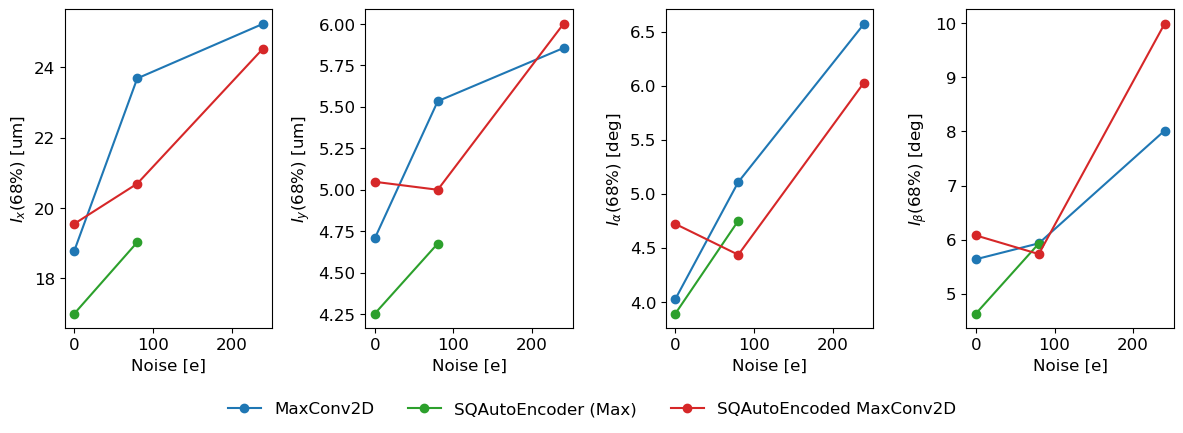

In [9]:

noise_pts = [0,80,240]

Conv2D_models = ['MC2D_T0e_2bit', 'MC2D_T80e_2bit', 'MC2D_T240e_2bit']
maxSQDAE_models = ['SQDAE_T0e_2x2bitEncoder', 'SQDAE_T80e_2x2bitEncoder', #'SQDAE_T240e_2x2bitEncoder'
                  ]
maxSQAE_Conv2D_models = ['SQDAE_MaxConv2D_T0e_2x2bitEncoder', 'SQDAE_MaxConv2D_T80e_2x2bitEncoder', 'SQDAE_MaxConv2D_T240e_2x2bitEncoder']
# slimSQDAE_models = ['SQDAE_T80e_2x2bitEncoder', 'SQDAE_T240e_2x2bitEncoder']

model_out = 'max'

vbl_names = {'x':r'$I_x(68\%)$ [um]', 'y':r'$I_y(68\%)$ [um]', 'A':r'$I_\alpha(68\%)$ [deg]', 'B':r'$I_\beta(68\%)$ [deg]'}

res_byNoise_SQDAE = get_ModelResWidths_byNoise(maxSQDAE_models, model_out = 'max')
res_byNoise_MC2D = get_ModelResWidths_byNoise(Conv2D_models, model_out = 'max')
res_byNoise_SQDAE_C2D_max = get_ModelResWidths_byNoise(maxSQAE_Conv2D_models, model_out = 'max')
print(res_byNoise_SQDAE_C2D_max)
fig, ax = plt.subplots(1,4,  figsize = (12,4))
for i, var in enumerate(vbl_names.keys()):
    ax[i].plot(res_byNoise_MC2D['noise'], res_byNoise_MC2D[f'{var}_width'], color = colors[0], marker = 'o')
    ax[i].plot(res_byNoise_SQDAE['noise'], res_byNoise_SQDAE[f'{var}_width'], color = colors[2], marker = 'o')
    ax[i].plot(res_byNoise_SQDAE_C2D_max['noise'], res_byNoise_SQDAE_C2D_max[f'{var}_width'], color = colors[3], marker = 'o')

    ax[i].set_ylabel(vbl_names[var])
    ax[i].set_xlabel('Noise [e]')

fig.legend(['MaxConv2D', 'SQAutoEncoder (Max)', 
            'SQAutoEncoded MaxConv2D' ], ncol = 4, frameon=False, loc='lower center', bbox_to_anchor = [0.5, -0.1])
fig.tight_layout()



MC2D_T0e_2bit
0
MC2D_T80e_2bit
1
MC2D_T240e_2bit
2
SQDAE_MaxConv2D_T0e_2x2bitEncoder
3
SQDAE_MaxConv2D_T80e_2x2bitEncoder
4
SQDAE_MaxConv2D_T240e_2x2bitEncoder
5


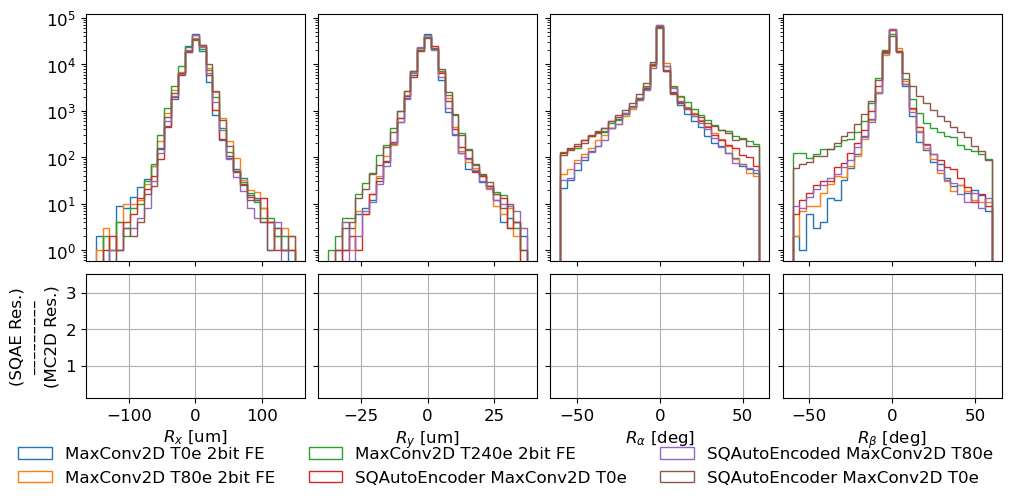

In [12]:
# OVERLAY RESIDUALS OF ALL TRAININGS --------------------------------------

# Pixel pitch (um)
xpitch = 50
ypitch = 12.5
# Thickness (um)
D = 100
# Size of pixel array
lenx = 16
leny = 16

baseline_80 = 'MC2D_T80e_2bit'
baseline_240 = 'MC2D_T240e_2bit'

Conv2D_models = ['MC2D_T0e_2bit', 'MC2D_T80e_2bit', 'MC2D_T240e_2bit']
maxSQAE_Conv2D_models = ['SQDAE_MaxConv2D_T0e_2x2bitEncoder', 'SQDAE_MaxConv2D_T80e_2x2bitEncoder', 'SQDAE_MaxConv2D_T240e_2x2bitEncoder']


# print(basehist)

fig, ax = plt.subplots(2,4,figsize=(10,4.5),sharey='row', sharex='col', constrained_layout=True, gridspec_kw={'height_ratios': [2, 1]},
)

# residuals = {}
df = {}
for i, m in enumerate(Conv2D_models+maxSQAE_Conv2D_models):
    print(m)
    path = f'./SQ_DAE_regression/residuals/{m}_residuals.parquet'
    df = pd.read_parquet(path)
    # df[m] = predictions
    # residuals[m] = {}

    if len(df.columns) == 0:
        continue
    
    # for i,df in residuals.items():
    
    print(i)

    # x
    ax[1][0].set_xlabel(r'$R_x$ [um]')
    x, x_bins, _ = ax[0][0].hist(df["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30),color=colors[i])
    ax[0][0].set_yscale('log')

    # y
    ax[1][1].set_xlabel(r'$R_y$ [um]')
    y, y_bins, _ = ax[0][1].hist(df["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30),color=colors[i])
    ax[0][1].set_yscale('log')

    # alpha
    ax[1][2].set_xlabel(r'$R_\alpha$ [deg]')
    A, A_bins, _ = ax[0][2].hist(df["residualA"],histtype='step',bins=np.linspace(-60,60,30),color=colors[i])
    ax[0][2].set_yscale('log')
    
    # beta
    ax[1][3].set_xlabel(r'$R_\beta$ [deg]')
    B, B_bins, _ = ax[0][3].hist(df["residualB"],histtype='step',bins=np.linspace(-60,60,30),color=colors[i])
    ax[0][3].set_yscale('log')
    
    ms =5
    # if (m!= baseline_80) and (m!=baseline_240):
    #     if 'T80e' in m or 'T0e' in m:
    #         print(m)
    #         baseline = baseline_80
    #     elif 'T240e' in m:
    #         baseline = baseline_240
    #     scrap_fig, scrap_ax = plt.subplots(1,1)
    #         # print(np.diff(x_bins)/2+x_bins[:-1])
    #         # print(np.diff(np.linspace(-3*xpitch,3*xpitch,30))/2+np.linspace(-3*xpitch,3*xpitch,30)[:-1])
    #     df_baseline = pd.read_parquet(f'./SQ_DAE_regression/residuals/{baseline}_residuals.parquet')
    
    #     x_baseline, _ , _ = scrap_ax.hist(df_baseline["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30))
    #     y_baseline, _ , _ = scrap_ax.hist(df_baseline["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30))
    #     A_baseline, _ , _ = scrap_ax.hist(df_baseline["residualA"],histtype='step',bins=np.linspace(-60,60,30))
    #     B_baseline, _ , _ = scrap_ax.hist(df_baseline["residualB"],histtype='step',bins=np.linspace(-60,60,30))
    #     plt.close(scrap_fig)
        
    #     x_ratio_err = x/x_baseline*(1/x+1/x_baseline)**0.5
    #     y_ratio_err = y/y_baseline*(1/y+1/y_baseline)**0.5
    #     A_ratio_err = A/A_baseline*(1/A+1/A_baseline)**0.5
    #     B_ratio_err = B/B_baseline*(1/B+1/B_baseline)**0.5
        
    #     ax[1][0].errorbar(np.diff(x_bins)/2+x_bins[:-1], x/x_baseline, yerr = x_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     ax[1][1].errorbar(np.diff(y_bins)/2+y_bins[:-1], y/y_baseline, yerr = y_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     ax[1][2].errorbar(np.diff(A_bins)/2+A_bins[:-1], A/A_baseline, yerr = A_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     ax[1][3].errorbar(np.diff(B_bins)/2+B_bins[:-1], B/B_baseline, yerr = B_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     # ax[1][3].set_xlim([-60,60])
    #     # ax[1][1].scatter(np.diff(y_bins)/2+y_bins[:-1], y/y_baseline, s = ms, color = colors[i])
        
    #     # ax[1][2].scatter(np.diff(A_bins)/2+A_bins[:-1], A/A_baseline, s = ms, color = colors[i])
        
    #     # ax[1][3].scatter(np.diff(B_bins)/2+B_bins[:-1], B/B_baseline, s = ms, color = colors[i])
        

fig.legend([train_dict[name]["name"] for name in Conv2D_models+maxSQAE_Conv2D_models ], ncol = 3, frameon=False, loc='lower center', fontsize=12, bbox_to_anchor = [0.5, -0.1])

# print(np.linspace(-3*xpitch,3*xpitch,29))
# print(np.linspace(-60,60,29))

ax[1][0].set_ylabel('(SQAE Res.)\n–––––––––\n(MC2D Res.)')
for a in ax[1, :]:
    a.set_ylim([0.1,3.5])
    a.grid()

# plt.suptitle(training_name);
    
#plt.tight_layout()
#plt.savefig('plots/'+training_name+'_residuals.png')

0
0
80
1
240
2


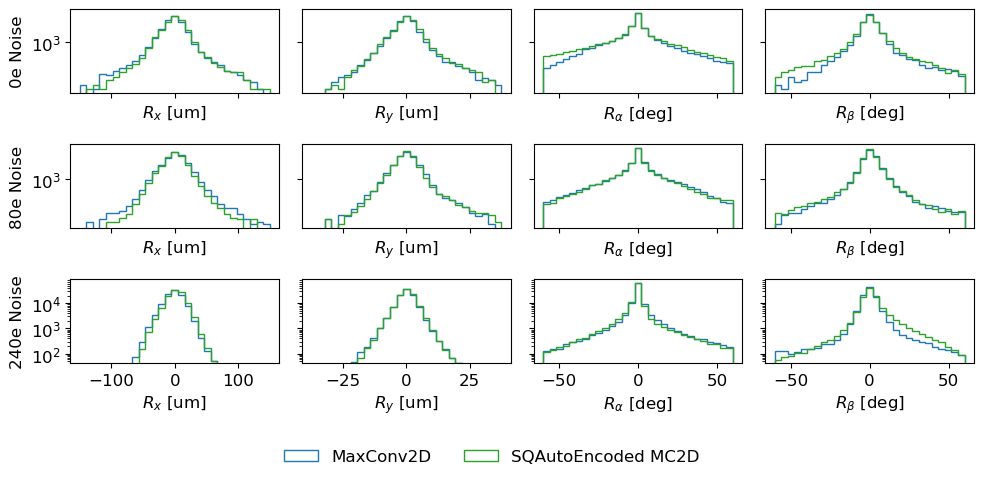

In [17]:
# OVERLAY RESIDUALS OF ALL TRAININGS --------------------------------------
with open('training_dict_new.json', 'r') as file:
    train_dict = json.load(file)
# Pixel pitch (um)
xpitch = 50
ypitch = 12.5
# Thickness (um)
D = 100
# Size of pixel array
lenx = 16
leny = 16

baseline_80 = 'MC2D_T80e_2bit'
baseline_240 = 'MC2D_T240e_2bit'

Conv2D_models = ['MC2D_T0e_2bit', 'MC2D_T80e_2bit', 'MC2D_T240e_2bit']
maxSQAE_Conv2D_models = ['SQDAE_MaxConv2D_T0e_2x2bitEncoder', 'SQDAE_MaxConv2D_T80e_2x2bitEncoder', 'SQDAE_MaxConv2D_T240e_2x2bitEncoder']

noise_levels = [0,80,240]

# print(basehist)

fig, ax = plt.subplots(3,4,figsize=(10,4.5),sharey='row', sharex='col',
)

# residuals = {}
df = {}
for i, n in enumerate(noise_levels):
    print(n)
    MC2D_name = f"MC2D_T{n}e_2bit"
    SQDAE_MC2D_name = f"SQDAE_MaxConv2D_T{n}e_2x2bitEncoder"
    
    MC2D_path = f'./SQ_DAE_regression/residuals/{MC2D_name}_residuals.parquet'
    SQDAE_MC2D_path = f'./SQ_DAE_regression/residuals/{SQDAE_MC2D_name}_residuals.parquet'

    df_MC2D = pd.read_parquet(MC2D_path)
    df_SQDAE_MC2D = pd.read_parquet(SQDAE_MC2D_path)
    # df[m] = predictions
    # residuals[m] = {}

    # if len(df.columns) == 0:
    #     continue
    
    # for i,df in residuals.items():
    
    print(i)
    ax[i][0].set_ylabel(f'{n}e Noise')

    # x
    ax[i][0].set_xlabel(r'$R_x$ [um]')
    x, x_bins, _ = ax[i][0].hist(df_MC2D["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30),color=colors[0])
    x, x_bins, _ = ax[i][0].hist(df_SQDAE_MC2D["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30),color=colors[2])
    ax[i][0].set_yscale('log')

    # y
    ax[i][1].set_xlabel(r'$R_y$ [um]')
    y, y_bins, _ = ax[i][1].hist(df_MC2D["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30),color=colors[0])
    y, y_bins, _ = ax[i][1].hist(df_SQDAE_MC2D["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30),color=colors[2])
    ax[i][1].set_yscale('log')

    # alpha
    ax[i][2].set_xlabel(r'$R_\alpha$ [deg]')
    A, A_bins, _ = ax[i][2].hist(df_MC2D["residualA"],histtype='step',bins=np.linspace(-60,60,30),color=colors[0])
    A, A_bins, _ = ax[i][2].hist(df_SQDAE_MC2D["residualA"],histtype='step',bins=np.linspace(-60,60,30),color=colors[2])
    ax[i][2].set_yscale('log')
    
    # beta
    ax[i][3].set_xlabel(r'$R_\beta$ [deg]')
    B, B_bins, _ = ax[i][3].hist(df_MC2D["residualB"],histtype='step',bins=np.linspace(-60,60,30),color=colors[0])
    B, B_bins, _ = ax[i][3].hist(df_SQDAE_MC2D["residualB"],histtype='step',bins=np.linspace(-60,60,30),color=colors[2])
    ax[i][3].set_yscale('log')
    
    ms =5
    # if (m!= baseline_80) and (m!=baseline_240):
    #     if 'T80e' in m or 'T0e' in m:
    #         print(m)
    #         baseline = baseline_80
    #     elif 'T240e' in m:
    #         baseline = baseline_240
    #     scrap_fig, scrap_ax = plt.subplots(1,1)
    #         # print(np.diff(x_bins)/2+x_bins[:-1])
    #         # print(np.diff(np.linspace(-3*xpitch,3*xpitch,30))/2+np.linspace(-3*xpitch,3*xpitch,30)[:-1])
    #     df_baseline = pd.read_parquet(f'./SQ_DAE_regression/residuals/{baseline}_residuals.parquet')
    
    #     x_baseline, _ , _ = scrap_ax.hist(df_baseline["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30))
    #     y_baseline, _ , _ = scrap_ax.hist(df_baseline["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30))
    #     A_baseline, _ , _ = scrap_ax.hist(df_baseline["residualA"],histtype='step',bins=np.linspace(-60,60,30))
    #     B_baseline, _ , _ = scrap_ax.hist(df_baseline["residualB"],histtype='step',bins=np.linspace(-60,60,30))
    #     plt.close(scrap_fig)
        
    #     x_ratio_err = x/x_baseline*(1/x+1/x_baseline)**0.5
    #     y_ratio_err = y/y_baseline*(1/y+1/y_baseline)**0.5
    #     A_ratio_err = A/A_baseline*(1/A+1/A_baseline)**0.5
    #     B_ratio_err = B/B_baseline*(1/B+1/B_baseline)**0.5
        
    #     ax[1][0].errorbar(np.diff(x_bins)/2+x_bins[:-1], x/x_baseline, yerr = x_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     ax[1][1].errorbar(np.diff(y_bins)/2+y_bins[:-1], y/y_baseline, yerr = y_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     ax[1][2].errorbar(np.diff(A_bins)/2+A_bins[:-1], A/A_baseline, yerr = A_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     ax[1][3].errorbar(np.diff(B_bins)/2+B_bins[:-1], B/B_baseline, yerr = B_ratio_err, color = colors[i], fmt = 'o', ms = 3)
    #     # ax[1][3].set_xlim([-60,60])
    #     # ax[1][1].scatter(np.diff(y_bins)/2+y_bins[:-1], y/y_baseline, s = ms, color = colors[i])
        
    #     # ax[1][2].scatter(np.diff(A_bins)/2+A_bins[:-1], A/A_baseline, s = ms, color = colors[i])
        
    #     # ax[1][3].scatter(np.diff(B_bins)/2+B_bins[:-1], B/B_baseline, s = ms, color = colors[i])
        

# fig.legend([train_dict[name]["name"] for name in Conv2D_models+maxSQAE_Conv2D_models ], ncol = 3, frameon=False, loc='lower center', fontsize=12, bbox_to_anchor = [0.5, -0.1])
fig.legend(['MaxConv2D', 'SQAutoEncoded MC2D'], ncol = 2, frameon=False, loc='lower center', fontsize=12, bbox_to_anchor = [0.5, -0.1])

# print(np.linspace(-3*xpitch,3*xpitch,29))
# print(np.linspace(-60,60,29))

# ax[1][0].set_ylabel('(SQAE Res.)\n–––––––––\n(MC2D Res.)')
# for a in ax[1, :]:
#     a.set_ylim([0.1,3.5])
#     a.grid()

# plt.suptitle(training_name);
    
plt.tight_layout()
#plt.savefig('plots/'+training_name+'_residuals.png')

In [24]:
###Slim Model plotting
SQDAE_path = './SQ_DAE/model-5d8a15ee-SQDAE_Categorical_v2_2bit_80eN_Target_0_30_856-checkpoints/'
path = './SQ_DAE_regression/model-085cfe04-SQDAE_SlimRegression_v2_Categorical2bit80eN_Target_0_30_856-checkpoints'
checkpoint_files = [os.path.join(path, f) for f in os.listdir(path) if f.endswith('.hdf5')]
best_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#Construct model
model = CreateSQAE_SlimReg_fromweights((16,16,2), SQDAE_path, FEBits = 2, OutBits = 2, n_filters=5, pool_size=2, 
                        conv_kernel_size=3, decoder_filters = 128)
print(f"Loading Slim regression model from {best_checkpoint}")
model.load_weights(best_checkpoint)
test_generator = validation_generator
sf = test_generator.labels_scale

scale_factor = {}
scale_factor['x'] = sf[0]
scale_factor['y'] = sf[1]
scale_factor['cotB'] = sf[2]

df = construct_df_slim(model, test_generator, scale_factor)
df.to_parquet('./SQ_DAE_regression/residuals/'+f"SQDAE_2x2bitEncoder_slim_residuals.parquet")
# residuals[i] = df


Loading model from ./SQ_DAE/model-5d8a15ee-SQDAE_Categorical_v2_2bit_80eN_Target_0_30_856-checkpoints/weights.979-t156886.0938-v161080.0156.hdf5
latent space layer:  q_activation_30 (None, 4, 4, 5)
Loading Slim regression model from ./SQ_DAE_regression/model-085cfe04-SQDAE_SlimRegression_v2_Categorical2bit80eN_Target_0_30_856-checkpoints/weights.1990-t41.04-v40.00.hdf5
21/21 [==============================] - 2s 81ms/step


100%|██████████| 21/21 [00:01<00:00, 15.77it/s]

0.041640606 -1.0083591 1.0082703


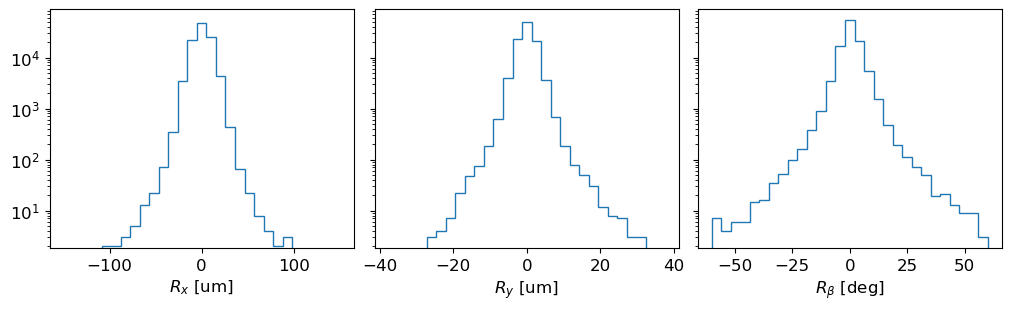

In [25]:
xpitch = 50
ypitch = 12.5
# Thickness (um)
D = 100
# Size of pixel array
lenx = 16
leny = 16

fig, ax = plt.subplots(1,3,figsize=(10,3),sharey='row', sharex='col', constrained_layout=True,
)

i=0
# for i,df in residuals.items():
# x
ax[0].set_xlabel(r'$R_x$ [um]')
x, _, _ = ax[0].hist(df["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30),color=colors[i])
ax[0].set_yscale('log')

# y
ax[1].set_xlabel(r'$R_y$ [um]')
y, _, _ = ax[1].hist(df["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30),color=colors[i])
ax[1].set_yscale('log')

# alpha

# beta
ax[2].set_xlabel(r'$R_\beta$ [deg]')
B, _, _ = ax[2].hist(df["residualB"],histtype='step',bins=np.linspace(-60,60,30),color=colors[i])
ax[2].set_yscale('log')

# ms =4

# if m!= 'MC2D_T80e_2bit':
#     ax[1][0].scatter(np.linspace(-3*xpitch,3*xpitch,29), x/x_baseline, s = ms, color = colors[i])
#     ax[1][1].scatter(np.linspace(-3*ypitch,3*ypitch,29), y/y_baseline, s = ms, color = colors[i])
#     ax[1][2].scatter(np.linspace(-60,60,29), A/A_baseline, s = ms, color = colors[i])
#     ax[1][3].scatter(np.linspace(-60,60,29), B/B_baseline, s = ms, color = colors[i])

# fig.legend(names, ncol = 4, frameon=False, loc='lower center', fontsize=12, bbox_to_anchor = [0.5, -0.1])

# print(np.linspace(-3*xpitch,3*xpitch,29))
# print(np.linspace(-60,60,29))

# ax[1][0].set_ylabel('(SQAE Res.)\n–––––––––\n(MC2D Res.)')
# for a in ax[1, :]:
#     a.set_ylim([0.2,3.2])
#     a.grid()

### 

In [22]:
residuals = {}

jennet_dir = "/uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models/"
ben_SQDAE_dir = '/SQ_DAE_regression/'
ben_main_dir = '../smart-pixels-ml/trained_models/'

trainings = [
    ben_SQDAE_dir+'/model-d11e02f3-SQDAE_regression_Categorical2bit_240eN_Target_0_30_856-checkpoints',
    ben_main_dir+'/model-74441133-SQMaxConv2D_T240e_v2-checkpoints',
    jennet_dir+'/model-58301193-MaxConv2D_SQ_80e_2bit-checkpoints',
    ben_SQDAE_dir+'/model-01193edd-SQDAE_regression_Categorical2bit_80eN_Target_0_30_856-checkpoints',
    ben_SQDAE_dir+'/model-9ee54816-SQDAE_regression_Categorical2bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints',
    jennet_dir+'/model-60350e7e-MaxConv2D_SQ_0e_2bit-checkpoints',

]

Tnames = ['MC2D_T240e_2bit', 'SQDAE_T240e_2x2bitEncoder',
          'MC2D_T80e_2bit', 'SQDAE_T80e_2x2bitEncoder', 'SQDAE_T80e_2x3bitEncoder',
          'MC2D_T0e_2bit',]
# names = {}
# names['MC2D_T240e_2bit'] = 'MaxConv2D T240e 2bit FE'
# names['SQDAE_T240e_2x2bitEncoder'] = 'SQAutoEncoder T240e 2bitFE 2bitEncoder'
# names['MC2D_T80e_2bit'] = 'MaxConv2D T80e 2bit FE'
# names['SQDAE_T80e_2x3bitEncoder'] = 'SQAutoEncoder T80e 2bitFE 3bitEncoder'
# names['SQDAE_T80e_2x2bitEncoder'] = 'SQAutoEncoder T80e 2bitFE 2bitEncoder'
# names['MC2D_T0e_2bit'] = 'MaxConv2D T0e 2bit FE'

jennet_tfrecords = "/uscms/home/jennetd/nobackup/smart-pixels/tfrecords"
ben_tfrecords = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/"
ben_TFR_80e = 'TFR_val/3sr_16x16_80eN_raw'
ben_TFR_CI_240e = 'TFR_val/3srCI_16x16_240eN_raw'

names = {}
names['MC2D_T240e_2bit'] = 'MaxConv2D T240e 2bit FE'
names['SQDAE_T240e_2x2bitEncoder'] = 'SQAutoEncoder T240e 2bitFE 2bitEncoder'
names['MC2D_T80e_2bit'] = 'MaxConv2D T80e 2bit FE'
names['SQDAE_T80e_2x3bitEncoder'] = 'SQAutoEncoder T80e 2bitFE 3bitEncoder'
names['SQDAE_T80e_2x2bitEncoder'] = 'SQAutoEncoder T80e 2bitFE 2bitEncoder'
names['MC2D_T0e_2bit'] = 'MaxConv2D T0e 2bit FE'

train_dict = {n:{'weights': trainings[i], 'tfr':None, 'name':names[n], 'noise':80} for i, n in enumerate(Tnames)}
print(train_dict)

# with open("training_dict.json", "w") as json_file:
#     json.dump(train_dict, json_file, indent=4)

print(ben_tfrecords+ben_TFR_80e)
print(ben_tfrecords+ben_TFR_CI_240e)
print(jennet_tfrecords+"/TFR_val/3sr_16x16_"+str(int(80))+'eNoise_test')

{'MC2D_T240e_2bit': {'weights': '/SQ_DAE_regression//model-d11e02f3-SQDAE_regression_Categorical2bit_240eN_Target_0_30_856-checkpoints', 'tfr': None, 'name': 'MaxConv2D T240e 2bit FE', 'noise': 80}, 'SQDAE_T240e_2x2bitEncoder': {'weights': '../smart-pixels-ml/trained_models//model-74441133-SQMaxConv2D_T240e_v2-checkpoints', 'tfr': None, 'name': 'SQAutoEncoder T240e 2bitFE 2bitEncoder', 'noise': 80}, 'MC2D_T80e_2bit': {'weights': '/uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models//model-58301193-MaxConv2D_SQ_80e_2bit-checkpoints', 'tfr': None, 'name': 'MaxConv2D T80e 2bit FE', 'noise': 80}, 'SQDAE_T80e_2x2bitEncoder': {'weights': '/SQ_DAE_regression//model-01193edd-SQDAE_regression_Categorical2bit_80eN_Target_0_30_856-checkpoints', 'tfr': None, 'name': 'SQAutoEncoder T80e 2bitFE 2bitEncoder', 'noise': 80}, 'SQDAE_T80e_2x3bitEncoder': {'weights': '/SQ_DAE_regression//model-9ee54816-SQDAE_regression_Categorical2bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints', 'tfr'

In [12]:
residuals = {}
df = {}
for j, m in enumerate(names):
    path = f'./SQ_DAE_regression/residuals/{m}_residuals.parquet'
    predictions = pd.read_parquet(path)
    df[m] = predictions
    residuals[m] = {}

    if len(predictions.columns) == 0:
        continue
                
    # Residuals for cotA 
    residuals[m]['mean_cotA'] = float(np.mean(predictions['residualcotA']))
    residuals[m]['std_cotA'] = float(np.std(predictions['residualcotA']))
    interval68_cotA = shortest_interval_68(predictions['residualcotA'], center_type='mean')
    residuals[m]['up68_cotA'] = interval68_cotA['error_high']
    residuals[m]['down68_cotA'] = interval68_cotA['error_low']

    # residuals for A
    residuals[m]['mean_A'] = float(np.mean(predictions['residualA']))
    residuals[m]['std_A'] = float(np.std(predictions['residualA']))
    interval68_A = shortest_interval_68(predictions['residualA'], center_type='mean')
    residuals[m]['up68_A'] = interval68_A['error_high']
    residuals[m]['down68_A'] = interval68_A['error_low']

    # Mean predicted uncertainty 
    residuals[m]['mean_upsigmax'] = float(np.mean(predictions['sigmax']))
    residuals[m]['mean_downsigmax'] = float(np.mean(predictions['sigmax']))
    residuals[m]['mean_upsigmay'] = float(np.mean(predictions['sigmay']))
    residuals[m]['mean_downsigmay'] = float(np.mean(predictions['sigmay']))
    residuals[m]['mean_upsigmacotA'] = float(np.mean(predictions['sigmacotA']))
    residuals[m]['mean_downsigmacotA'] = float(np.mean(predictions['sigmacotA']))
    residuals[m]['mean_upsigmaA'] = float(np.mean(abs(inverse_cot(predictions['cotA'].values + predictions['sigmacotA'].values)*180/np.pi - predictions['A'].values)))
    residuals[m]['mean_downsigmaA'] = float(np.mean(abs(inverse_cot(predictions['cotA'].values - predictions['sigmacotA'].values)*180/np.pi - predictions['A'].values)))            
    residuals[m]['mean_upsigmacotB'] = float(np.mean(predictions['sigmacotB']))
    residuals[m]['mean_downsigmacotB'] = float(np.mean(predictions['sigmacotB']))
    residuals[m]['mean_upsigmaB'] = float(np.mean(abs(inverse_cot(predictions['cotB'].values + predictions['sigmacotB'].values)*180/np.pi - predictions['B'].values)))
    residuals[m]['mean_downsigmaB'] = float(np.mean(abs(inverse_cot(predictions['cotB'].values - predictions['sigmacotB'].values)*180/np.pi - predictions['B'].values)))

    # Residuals for x and y (microns)
    for v in ['x','y']:
        # Mean
        residuals[m]['mean_'+v] = float(np.mean(predictions['residual'+v]))
        # Std -- replace with smallest window containing 68%
        residuals[m]['std_'+v] = float(np.std(predictions['residual'+v]))

        interval68 = shortest_interval_68(predictions['residual'+v], center_type='mean')
        residuals[m]['up68_'+v] = interval68['error_high']
        residuals[m]['down68_'+v] = interval68['error_low']

    # Residuals for cotB
    residuals[m]['mean_cotB'] = float(np.mean(predictions['residualcotB']))
    residuals[m]['std_cotB'] = float(np.std(predictions['residualcotB']))
    interval68_cotB = shortest_interval_68(predictions['residualcotB'], center_type='mean')
    residuals[m]['up68_cotB'] = interval68_cotB['error_high']
    residuals[m]['down68_cotB'] = interval68_cotB['error_low']

    # Residuals for B
    residuals[m]['mean_B'] = float(np.mean(predictions['residualB']))
    residuals[m]['std_B'] = float(np.std(predictions['residualB']))
    interval68_B = shortest_interval_68(predictions['residualB'], center_type='mean')
    residuals[m]['up68_B'] = interval68_B['error_high']
    residuals[m]['down68_B'] = interval68_B['error_low']
    
with open('./SQ_DAE_regression/residuals/residuals.json', 'w') as fp:
    json.dump(residuals, fp)